# Laboratorio dirigido 12 — Analítica de procesos internos
**Caso:** monitoreo de la temperatura de una máquina industrial y priorización de alertas operativas.
**Datos reales:** Numenta Anomaly Benchmark (NAB), serie `machine_temperature_system_failure`: lecturas cada 5 minutos del sensor de temperatura de un componente interno de una máquina industrial grande, del 2 de diciembre de 2013 al 19 de febrero de 2014. La fuente no indica la unidad de medida.
**Pregunta:** ¿qué lecturas y qué días merecen revisión primero, sin acusar una falla a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.

## Objetivos y teoría
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día. Una alerta es un motivo para investigar, no una prueba de falla.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y la fuente no explica la causa de cada una.

## Paso 1. Cargar datos abiertos y conservar trazabilidad
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [ ]:
!pip -q install scikit-learn
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
BASE_URL = "https://raw.githubusercontent.com/numenta/NAB/master/"
URL_DATOS = BASE_URL + "data/realKnownCause/machine_temperature_system_failure.csv"
URL_ETIQ = BASE_URL + "labels/combined_windows.json"
raw = pd.read_csv(URL_DATOS, parse_dates=["timestamp"])
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())
print(raw.head())

Filas originales: 22695 Columnas: ['timestamp', 'value']
Desde 2013-12-02 21:15:00 hasta 2014-02-19 15:25:00
            timestamp      value
0 2013-12-02 21:15:00  73.967322
1 2013-12-02 21:20:00  74.935882
2 2013-12-02 21:25:00  76.124162
3 2013-12-02 21:30:00  78.140707
4 2013-12-02 21:35:00  79.329836


## Paso 2. Reglas de calidad y variables derivadas
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se trabaja con días completos: del 3 de diciembre de 2013 al 18 de febrero de 2014. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas resumen la última hora (12 lecturas): media, desviación y cambio respecto de hace una hora.

In [ ]:
# Marcas de tiempo repetidas: se conserva la primera lectura de cada instante
repetidas = raw.timestamp.duplicated(keep="first")
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
# Se comprueba que todas las lecturas están separadas por 5 minutos
fuera_de_paso = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=5)).sum())
# Solo días completos: el primer y el último día de la fuente están incompletos
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))
print("Lecturas fuera del paso de 5 min:", fuera_de_paso, "· lecturas en días completos:", len(df))
print(df.value.describe().round(2))
print("Lecturas por debajo de 20:", int((df.value < 20).sum()))
# Variables derivadas de la última hora; las 11 primeras lecturas no tienen historia suficiente
feat = pd.DataFrame({"valor": df.value,
                     "media_1h": df.value.rolling(12).mean(),
                     "desv_1h": df.value.rolling(12).std(),
                     "cambio_1h": df.value.diff(12)}).dropna()
print("Lecturas con variables completas:", len(feat))

Marcas repetidas: 12 · lecturas útiles: 22683
Lecturas fuera del paso de 5 min: 0 · lecturas en días completos: 22464
count    22464.00
mean        85.87
std         13.80
min          2.08
25%         83.03
50%         89.33
75%         94.00
max        108.51
Name: value, dtype: float64
Lecturas por debajo de 20: 12
Lecturas con variables completas: 22452


## Paso 3. Separar línea base y periodo de seguimiento
Línea base: 3 al 31 de diciembre de 2013. Seguimiento: 1 de enero al 18 de febrero de 2014. La separación se fija antes de examinar las alertas. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [ ]:
CORTE = pd.Timestamp("2014-01-01")
base = feat.index < CORTE
# Ventanas de anomalía señaladas por los autores de NAB (solo referencia para contrastar)
etiquetas = json.load(urllib.request.urlopen(URL_ETIQ))["realKnownCause/machine_temperature_system_failure.csv"]
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]
en_ventana = pd.Series(False, index=feat.index)
for a, b in ventanas:
    en_ventana.loc[a:b] = True
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")
print("Ventanas de referencia:", [(str(a)[:16], str(b)[:16]) for a, b in ventanas])
assert base.sum() > 5000 and (~base).sum() > 10000

Línea base: 8340 lecturas · Seguimiento: 14112 lecturas
Ventanas de referencia: [('2013-12-10 06:25', '2013-12-12 05:35'), ('2013-12-15 17:50', '2013-12-17 17:00'), ('2014-01-27 14:20', '2014-01-29 13:30'), ('2014-02-07 14:55', '2014-02-09 14:05')]


## Paso 4. Detectar lecturas inusuales
El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa física de una lectura.

In [ ]:
modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
# El modelo aprende lo normal solo con la línea base
modelo.fit(feat.loc[base])
# Puntuación de rareza: mayor valor significa lectura más atípica
feat["score"] = -modelo.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])
# Umbral: percentil 99 de las puntuaciones de la línea base
umbral = feat.loc[base, "score"].quantile(0.99)
feat["alerta"] = feat.score >= umbral
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

Umbral: 0.606
Alertas en la línea base: 84
Alertas en el seguimiento: 495


## Paso 5. Carta p con límites diarios
La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día. Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [ ]:
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
pbar = feat.loc[base, "alerta"].mean()
diario["tasa"] = diario.alertas / diario.lecturas
diario["lsc"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas)
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)
seguimiento = diario.loc[CORTE:].copy()
print("p̄ =", round(pbar, 5))
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("alertas > 0").to_string())
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])
print("Días de la línea base fuera de límites:", int(diario.loc[:CORTE - pd.Timedelta(days=1), "fuera"].sum()), "de", int((diario.index < CORTE).sum()))

p̄ = 0.01007
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-01-02       288        5  0.017361  0.027724  False
2014-01-05       288        8  0.027778  0.027724   True
2014-01-12       288       13  0.045139  0.027724   True
2014-01-16       288        8  0.027778  0.027724   True
2014-01-24       288       12  0.041667  0.027724   True
2014-01-31       288        1  0.003472  0.027724  False
2014-02-03       288       25  0.086806  0.027724   True
2014-02-07       288        5  0.017361  0.027724  False
2014-02-08       288      246  0.854167  0.027724   True
2014-02-09       288      158  0.548611  0.027724   True
2014-02-13       288        8  0.027778  0.027724   True
2014-02-14       288        6  0.020833  0.027724  False
Días fuera de control en el seguimiento: ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base fuera de lími

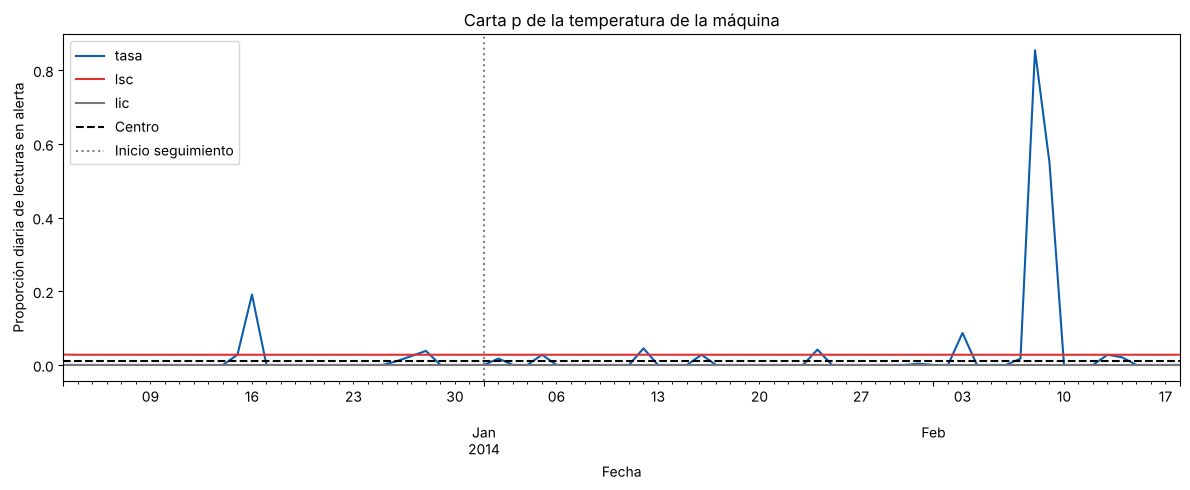

In [ ]:
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])
ax.axhline(pbar, color="black", ls="--", label="Centro")
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la temperatura de la máquina")
ax.legend(); plt.tight_layout(); plt.show()

## Paso 6. Convertir alertas en una cola de revisión
Un **episodio** agrupa las alertas separadas por 30 minutos o menos: es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

In [ ]:
CAPACIDAD_DIA = 1
alertas = feat.loc[feat.alerta, ["score"]].reset_index()
# Un episodio nuevo empieza cuando pasan más de 30 minutos desde la alerta anterior
alertas["episodio"] = (alertas.timestamp.diff() > pd.Timedelta(minutes=30)).cumsum()
episodios = alertas.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                            lecturas=("score", "size"), score_max=("score", "max"))
episodios["dia"] = episodios.inicio.dt.normalize()
# Coincidencia con una ventana de referencia: superposición en el tiempo
episodios["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(episodios.inicio, episodios.fin)]
ep = episodios[episodios.inicio >= CORTE].copy()
# Prioridad dentro de cada día por puntuación máxima; se revisan los primeros hasta completar la capacidad
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))
display(ep.sort_values("score_max", ascending=False).head(10).round(3))

Episodios en el seguimiento: 17 · revisables: 11 · en cola: 6
Episodios que coinciden con una ventana: 2
Lecturas en alerta dentro de ventanas: 404 de 495


/tmp/ipykernel_2151/2144810969.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ep.sort_values("score_max", ascending=False).head(10).round(3))


,inicio,fin,lecturas,score_max,dia,en_ventana,orden_dia,revisable
episodio,,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,403,0.793,2014-02-08,True,1.0,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,17,0.761,2014-02-03,False,1.0,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,12,0.679,2014-01-24,False,1.0,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,8,0.660,2014-02-03,False,2.0,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,8,0.644,2014-01-12,False,1.0,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,4,0.640,2014-02-13,False,1.0,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,5,0.640,2014-01-12,False,2.0,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,6,0.637,2014-01-16,False,1.0,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,8,0.634,2014-01-05,False,1.0,True


## Paso 7. Sensibilidad del umbral
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [ ]:
filas = []
for q in [0.98, 0.99, 0.995]:
    corte_q = feat.loc[base, "score"].quantile(q)
    a = feat.score >= corte_q
    pq = a[base].mean()
    n_dia = a.groupby(a.index.normalize()).size()
    k_dia = a.groupby(a.index.normalize()).sum()
    lsc_q = pq + 3 * np.sqrt(pq * (1 - pq) / n_dia)
    fuera_q = int(((k_dia / n_dia > lsc_q) & (n_dia.index >= CORTE)).sum())
    ix = a[a].index.to_series()
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max()})
    e = e[e.inicio >= CORTE]
    e["en_ventana"] = [any((i <= b2) and (f >= a2) for a2, b2 in ventanas) for i, f in zip(e.inicio, e.fin)]
    cola = int((e.groupby(e.inicio.dt.normalize()).size() - CAPACIDAD_DIA).clip(lower=0).sum())
    filas.append({"percentil_base": q, "umbral": corte_q, "alertas": int(a[~base].sum()), "episodios": len(e),
                  "en_ventana": int(e.en_ventana.sum()), "dias_fuera": fuera_q, "cola": cola})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.559949,686,31,4,11,15
1,0.990,0.606017,495,17,2,8,6
2,0.995,0.692755,31,3,2,3,0


## Tres retos individuales — diez ítems
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### Pregunta 1.1
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.

In [ ]:
# Evidencia para la pregunta 1.1 (calidad de datos)
print("Filas originales:", len(raw), "· marcas repetidas:", int(repetidas.sum()))
rep = raw[raw.timestamp.duplicated(keep=False)].sort_values("timestamp")
print("¿Las repetidas traen el mismo valor?", bool((rep.groupby("timestamp").value.nunique() == 1).all()))
print("Huecos (lecturas fuera del paso de 5 min):", fuera_de_paso)
esperadas = int((pd.Timestamp("2014-02-18 23:55") - pd.Timestamp("2013-12-03")).total_seconds() / 300 + 1)
print("Lecturas esperadas en días completos:", esperadas, "· presentes:", len(df))
print("Rango temporal original:", raw.timestamp.min(), "->", raw.timestamp.max())
print("Rango de valores (días completos):", round(df.value.min(), 2), "a", round(df.value.max(), 2))
bajas = df[df.value < 20]
print("Lecturas < 20:", len(bajas), "· desde", bajas.index.min(), "hasta", bajas.index.max())
print(df.loc["2013-12-16 16:15":"2013-12-16 17:45", "value"].round(1).to_string())

Filas originales: 22695 · marcas repetidas: 12
¿Las repetidas traen el mismo valor? False
Huecos (lecturas fuera del paso de 5 min): 0
Lecturas esperadas en días completos: 22464 · presentes: 22464
Rango temporal original: 2013-12-02 21:15:00 -> 2014-02-19 15:25:00
Rango de valores (días completos): 2.08 a 108.51
Lecturas < 20: 12 · desde 2013-12-16 16:35:00 hasta 2013-12-16 17:30:00
timestamp
2013-12-16 16:15:00    25.7
2013-12-16 16:20:00    23.8
2013-12-16 16:25:00    23.0
2013-12-16 16:30:00    21.7
2013-12-16 16:35:00    19.3
2013-12-16 16:40:00    18.6
2013-12-16 16:45:00    16.5
2013-12-16 16:50:00    14.7
2013-12-16 16:55:00    12.4
2013-12-16 17:00:00     9.6
2013-12-16 17:05:00    10.0
2013-12-16 17:10:00     6.9
2013-12-16 17:15:00     6.4
2013-12-16 17:20:00     4.1
2013-12-16 17:25:00     2.1
2013-12-16 17:30:00    12.1
2013-12-16 17:35:00    32.0
2013-12-16 17:40:00    41.3
2013-12-16 17:45:00    41.2


**Respuesta:**

- **Marcas repetidas:** 12 de 22 695 filas originales. Los duplicados traían valores distintos entre sí, de modo que conservar la primera lectura es una regla analítica declarada y no una verdad de la fuente.
- **Huecos:** 0. Tras quitar las repetidas ninguna lectura queda fuera del paso de 5 minutos, y los días completos (3 dic a 18 feb) tienen exactamente las 22 464 lecturas esperadas (78 días × 288).
- **Rango:** la serie original va del 2 dic 2013 21:15 al 19 feb 2014 15:25. En días completos los valores van de 2,08 a 108,51 (media 85,87; mediana 89,33; la fuente no indica la unidad).
- **Lecturas muy bajas:** hay 12 por debajo de 20, todas el 16 dic 2013 entre las 16:35 y las 17:30, con mínimo de 2,08 a las 17:25. Ese día cae dentro de la primera ventana de NAB.

Dos causas posibles: (1) una parada o apagado real del componente: la serie baja de forma continua de 25,7 (16:15) a 2,1 (17:25) y luego rebota a 32,0 a las 17:35, un patrón compatible con enfriamiento y rearranque; (2) un problema de medición, como sensor desconectado, descalibrado o fallo de transmisión que reporta un valor irreal. Con solo estos datos no se puede distinguir una de otra, hace falta la bitácora de mantenimiento.

### Pregunta 1.2
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.

**Respuesta:** (cifras del top 10 con el umbral p99 = 0,6060; la unidad de temperatura no está indicada)

**Episodio A (el de mayor prioridad):** inicia el 8 feb 2014 a las 02:40 y termina el 9 feb a las 13:05, unas 34,5 horas (2 070 min), con 403 lecturas en alerta y puntuación máxima 0,793. En él la lectura baja hasta 25,9 y la desviación de la última hora llega a 21,0; el 7-8 feb la temperatura cayó desde ~93 hasta ~29-35 y el 9 feb al mediodía volvió a ~88-92. Coincide con la ventana de NAB del 7 al 9 feb.
- *Explicación 1:* parada programada o paro por avería de la máquina, con enfriamiento prolongado y rearranque el 9 feb.
- *Explicación 2:* falla del sistema de calentamiento o refrigeración, o del sensor, que dejó la lectura estancada en un nivel bajo.

**Episodio B:** inicia el 3 feb a las 11:50 y termina a las 13:10 (85 min), con 17 lecturas en alerta y puntuación máxima 0,761. Entre las 10:00 y las 11:45 la lectura estaba en ~44-48 y pasó a 68 a las 12:00 y 93 a las 12:45; el cambio en una hora llega a +50 y la desviación a 18,5. No coincide con ninguna ventana de NAB.
- *Explicación 1:* arranque posterior a una parada (el episodio vecino del mismo día, 00:10-00:45, muestra una caída de unos 15 a 23 en una hora), es decir, un ciclo apagado-encendido.
- *Explicación 2:* intervención de mantenimiento o cambio brusco de carga o set point, o reconexión de un sensor.

### Pregunta 1.3
Identifique los días fuera de control e indique por qué son señales para investigar.

**Respuesta:** con p̄ = 0,01007 y n = 288 lecturas por día, el límite superior es 0,0277 (más de 7,98 alertas al día). En el seguimiento hay **8 días fuera de control**:

| Día | Alertas | Tasa |
|---|---|---|
| 5 ene | 8 | 2,8 % |
| 12 ene | 13 | 4,5 % |
| 16 ene | 8 | 2,8 % |
| 24 ene | 12 | 4,2 % |
| 3 feb | 25 | 8,7 % |
| 8 feb | 246 | 85,4 % |
| 9 feb | 158 | 54,9 % |
| 13 feb | 8 | 2,8 % |

Son señales para investigar porque la proporción de lecturas atípicas supera lo que la línea base hacía esperar (unas 3 alertas por día). Pero no prueban una falla: 5 ene, 16 ene y 13 feb superan el límite apenas por una alerta; las lecturas contiguas están correlacionadas, así que el supuesto binomial es una aproximación y los límites son optimistas (en la propia línea base 3 de 29 días quedaron fuera); y se evalúan 49 días, de modo que algún falso positivo es esperable. El 8 y 9 feb son de otra magnitud y coinciden con la ventana de NAB.

### Pregunta 1.4
Proponga tres verificaciones externas antes de concluir una falla.

**Respuesta:** antes de hablar de falla propondría tres verificaciones externas:

1. **Bitácora de mantenimiento y de operación** (órdenes de trabajo, paradas y arranques, cambios de set point) del 16 dic, 24 ene, 3 feb y 7-9 feb, para ver si hubo una intervención o parada planificada que explique el patrón.
2. **Estado del sensor y variables complementarias**: calibración o reemplazo del sensor, comparación con un sensor redundante y con otras señales de la máquina (corriente, vibración, presión, carga). Una temperatura de 2,1 el 16 dic debe confirmarse contra ellas.
3. **Registros de producción, alarmas y calidad**: alarmas del sistema de control, tiempo de línea detenida, rechazos o reclamos de ese periodo y una consulta a los operadores del turno, para saber si el cambio tuvo consecuencia operativa real.

### Pregunta 2.1
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.

In [ ]:
# Evidencia para 2.1/2.2: qué ventanas y qué episodios quedan con cada umbral
for q in [0.98, 0.99, 0.995]:
    cq = feat.loc[base, "score"].quantile(q)
    a = feat.score >= cq
    ix = a[a].index.to_series()
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max(), "lecturas": ix.groupby(nuevo).size()})
    e["score_max"] = [feat.score[i:f].max() for i, f in zip(e.inicio, e.fin)]
    e = e[e.inicio >= CORTE]
    e["dia"] = e.inicio.dt.normalize()
    e["rank_dia"] = e.groupby("dia").score_max.rank(ascending=False, method="first")
    rev = e[e.rank_dia == 1]
    print(f"== percentil {q}: umbral={cq:.4f} · episodios={len(e)} · revisados (1/día)={len(rev)} · en cola={len(e)-len(rev)}")
    print("   Ventanas de seguimiento tocadas:", [str(a_)[:10] for a_, b_ in ventanas if a_ >= CORTE and ((e.inicio <= b_) & (e.fin >= a_)).any()])
    if q == 0.995: print(e[["inicio", "fin", "lecturas", "score_max"]].round(3).to_string())

== percentil 0.98: umbral=0.5599 · episodios=31 · revisados (1/día)=16 · en cola=15
   Ventanas de seguimiento tocadas: ['2014-01-27', '2014-02-07']
== percentil 0.99: umbral=0.6060 · episodios=17 · revisados (1/día)=11 · en cola=6
   Ventanas de seguimiento tocadas: ['2014-02-07']
== percentil 0.995: umbral=0.6928 · episodios=3 · revisados (1/día)=3 · en cola=0
   Ventanas de seguimiento tocadas: ['2014-02-07']
                       inicio                 fin  lecturas  score_max
timestamp                                                             
1         2014-02-03 12:05:00 2014-02-03 12:55:00        11      0.761
2         2014-02-08 16:00:00 2014-02-08 16:30:00         7      0.702
3         2014-02-09 11:50:00 2014-02-09 12:50:00        13      0.793


/tmp/ipykernel_2151/536097351.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  if q == 0.995: print(e[["inicio", "fin", "lecturas", "score_max"]].round(3).to_string())


**Respuesta:**

| Percentil base | Umbral | Alertas seguimiento | Episodios | Episodios en ventana | Días fuera de control | Cola (1 ep/día) |
|---|---|---|---|---|---|---|
| 98 | 0,5599 | 686 | 31 | 4 | 11 | 15 |
| 99 | 0,6060 | 495 | 17 | 2 | 8 | 6 |
| 99,5 | 0,6928 | 31 | 3 | 2 | 3 | 0 |

Subir el percentil reduce todo de forma fuerte: de 686 a 31 alertas y de 31 a 3 episodios. Con p98 se llega a tocar las dos ventanas del seguimiento (27 ene y 7 feb), pero genera 31 episodios en 16 días y 15 quedan sin revisar. Con p99 solo se toca la ventana del 7 feb y la cola es de 6 episodios. Con p99,5 la cola es cero y también se toca la ventana del 7 feb, pero se descartan casi todos los episodios cortos. Ningún umbral detecta la ventana del 27 ene salvo p98. Ojo: la línea base ya tiene 84 alertas (p99) o 167 (p98) por construcción, es decir, el 1 % o 2 % de lecturas normales siempre se marcan.

### Pregunta 2.2
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.

**Respuesta:** con capacidad de una revisión por día defendería el **percentil 99,5 (umbral 0,6928)**: produce 3 episodios en 3 días distintos (3 feb 12:05, puntuación 0,761; 8 feb 16:00, 0,702; 9 feb 11:50, 0,793), cola cero, 3 días fuera de control, y toca la ventana del 7-9 feb. Es la única opción en la que cada episodio se puede revisar el mismo día, lo que mantiene la alerta creíble para el equipo; p99 deja 6 episodios sin atender y p98 deja 15.

**Costo de oportunidad:** se pasa de 17 a 3 episodios, es decir, se dejan de mirar los otros 14. Entre ellos el del 24 ene 12:50 (12 lecturas, puntuación 0,679), los del 12 ene, 16 ene y 13 feb, y el aviso de las 07:50 del 7 feb (puntuación 0,633), que fue previo a la caída del 7-9 feb. También se pierde la única oportunidad (con p98) de tocar la ventana del 27 ene. Si el equipo ampliara su capacidad a 2 o más revisiones por día, p99 sería la mejor opción. La elección se hizo por capacidad, no para acertar las ventanas de NAB.

### Pregunta 2.3
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

In [ ]:
# Pregunta 2.3: desfase entre el inicio de cada ventana y el primer episodio (umbral p99)
ep_all = episodios[episodios.inicio >= CORTE]
for a_, b_ in ventanas:
    if a_ < CORTE: continue
    dentro = ep_all[(ep_all.inicio <= b_) & (ep_all.fin >= a_)]
    previo = ep_all[ep_all.fin < a_].tail(1)
    posterior = ep_all[ep_all.inicio > b_].head(1)
    print("Ventana", a_, "->", b_)
    if len(dentro):
        p = dentro.inicio.min()
        print("  Primer episodio superpuesto:", p, "· desfase:", round((p - a_).total_seconds() / 3600, 2), "h")
    else:
        print("  Ningún episodio se superpone con la ventana")
    if len(previo): print("  Último episodio previo:", previo.inicio.iloc[0], "· desfase:", round((previo.inicio.iloc[0] - a_).total_seconds() / 3600, 1), "h")
    if len(posterior): print("  Primer episodio posterior:", posterior.inicio.iloc[0], "· desfase:", round((posterior.inicio.iloc[0] - a_).total_seconds() / 3600, 1), "h")
print("Valores el 7-9 feb (mín/media/máx por 6 h):")
print(feat.valor.loc["2014-02-07":"2014-02-09"].resample("6h").agg(["min", "mean", "max"]).round(1).to_string())

Ventana 2014-01-27 14:20:00 -> 2014-01-29 13:30:00
  Ningún episodio se superpone con la ventana
  Último episodio previo: 2014-01-24 12:50:00 · desfase: -73.5 h
  Primer episodio posterior: 2014-01-31 10:20:00 · desfase: 92.0 h
Ventana 2014-02-07 14:55:00 -> 2014-02-09 14:05:00
  Primer episodio superpuesto: 2014-02-08 02:00:00 · desfase: 11.08 h
  Último episodio previo: 2014-02-07 07:50:00 · desfase: -7.1 h
  Primer episodio posterior: 2014-02-13 19:30:00 · desfase: 148.6 h
Valores el 7-9 feb (mín/media/máx por 6 h):
                      min  mean   max
timestamp                            
2014-02-07 00:00:00  91.1  93.3  96.7
2014-02-07 06:00:00  61.0  71.4  92.1
2014-02-07 12:00:00  52.8  57.5  62.3
2014-02-07 18:00:00  45.4  49.7  53.5
2014-02-08 00:00:00  37.0  41.9  46.4
2014-02-08 06:00:00  29.6  34.0  38.6
2014-02-08 12:00:00  25.9  29.2  32.5
2014-02-08 18:00:00  30.8  32.9  35.7
2014-02-09 00:00:00  30.8  33.4  35.8
2014-02-09 06:00:00  29.4  31.1  44.0
2014-02-09 12:00:0

**Respuesta:** (umbral p99, seguimiento)

- **Ventana 27 ene 14:20 → 29 ene 13:30:** ningún episodio se superpone con ella. El último episodio previo fue el 24 ene 12:50 (−73,5 h respecto al inicio) y el primero posterior el 31 ene 10:20 (+92,0 h).
- **Ventana 7 feb 14:55 → 9 feb 14:05:** el primer episodio que se superpone empieza el 8 feb 02:00, **11,1 horas después** del inicio. Antes hubo un episodio el 7 feb 07:50 (−7,1 h), pero termina antes de que empiece la ventana y no se superpone con ella.

Esa diferencia no demuestra capacidad de predicción: (1) las ventanas de NAB son aproximadas y se fijan después de conocer el evento, así que su inicio no es el momento real de la falla; (2) el modelo usa la lectura y la última hora, de modo que alerta cuando el patrón ya cambió (la temperatura ya venía cayendo desde la mañana del 7 feb: de ~93 a ~71 de media entre las 06:00 y las 12:00); (3) es un solo caso con una sola coincidencia (2 de 17 episodios coinciden con una ventana) y la otra ventana no fue detectada; (4) los otros 15 episodios no se relacionan con ninguna ventana, de modo que no se puede estimar la tasa de falsas alarmas ni el aviso anticipado en general.

### Pregunta 3.1
Repita la carta p con una línea base ampliada del 3 de diciembre al 15 de enero, reentrenando el modelo, e informe cambios.

In [ ]:
# Pregunta 3.1: línea base ampliada (3 dic - 15 ene), reentrenando
cols = ["valor", "media_1h", "desv_1h", "cambio_1h"]
CORTE2 = pd.Timestamp("2014-01-16")
base2 = feat.index < CORTE2
m2 = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1).fit(feat.loc[base2, cols])
f2 = feat.copy()
f2["score"] = -m2.score_samples(f2[cols])
u2 = f2.loc[base2, "score"].quantile(0.99)
f2["alerta"] = f2.score >= u2
p2 = f2.loc[base2, "alerta"].mean()
d2 = f2.groupby(f2.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
d2["tasa"] = d2.alertas / d2.lecturas
d2["lsc"] = p2 + 3 * np.sqrt(p2 * (1 - p2) / d2.lecturas)
d2["fuera"] = d2.tasa > d2.lsc
print("Línea base ampliada:", int(base2.sum()), "lecturas · umbral:", round(u2, 4), "(antes", round(umbral, 4), ") · p̄:", round(p2, 5), "(antes", round(pbar, 5), ")")
print("Alertas en el seguimiento nuevo (desde 16 ene):", int(f2.loc[~base2, "alerta"].sum()), "· con la línea base original, mismo tramo:", int(feat.loc[feat.index >= CORTE2, "alerta"].sum()))
print("Días fuera de control desde 16 ene (base ampliada):", [str(x)[:10] for x in d2.loc[CORTE2:].index[d2.loc[CORTE2:].fuera]])
print("Días fuera de control desde 16 ene (base original):  ", [str(x)[:10] for x in diario.loc[CORTE2:].index[diario.loc[CORTE2:].fuera]])
print("Días de la línea base ampliada fuera de límites:", [str(x)[:10] for x in d2.loc[:CORTE2 - pd.Timedelta(days=1)].index[d2.loc[:CORTE2 - pd.Timedelta(days=1)].fuera]])

Línea base ampliada: 12660 lecturas · umbral: 0.5997 (antes 0.606 ) · p̄: 0.01003 (antes 0.01007 )
Alertas en el seguimiento nuevo (desde 16 ene): 501 · con la línea base original, mismo tramo: 469
Días fuera de control desde 16 ene (base ampliada): ['2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días fuera de control desde 16 ene (base original):   ['2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base ampliada fuera de límites: ['2013-12-15', '2013-12-16', '2013-12-26', '2013-12-27', '2013-12-28', '2014-01-05', '2014-01-12']


**Respuesta:** con la línea base ampliada (12 660 lecturas, 3 dic al 15 ene) el cambio es pequeño:

- El umbral baja de 0,6060 a 0,5997 y p̄ pasa de 0,01007 a 0,01003, así que el límite superior casi no se mueve (0,0276).
- En el tramo desde el 16 ene hay 501 alertas, contra 469 con la línea base original (+32).
- Los días fuera de control desde el 16 ene son los mismos 6 en ambos casos: 16 ene, 24 ene, 3 feb, 8 feb, 9 feb y 13 feb.
- El 5 y 12 ene dejan de evaluarse como seguimiento y pasan a formar parte de la línea base. Con ella aumentan los días base fuera de límites (7 de 44 frente a 3 de 29), señal de que la línea base ampliada contiene eventos atípicos (15-16 dic, 26-28 dic, 5 y 12 ene).

Conclusión: las señales principales (3 feb y 8-9 feb) son robustas al cambio de la línea base. Pero si la base incluye días anómalos, el modelo aprende en parte lo anómalo como normal; conviene revisar y limpiar la línea base antes de ampliarla.

### Pregunta 3.2
Compare el modelo con las cuatro variables y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.

In [ ]:
# Pregunta 3.2: modelo con cuatro variables vs. modelo que usa solo la lectura (valor)
def episodios_de(a):
    ix = a[a].index.to_series()
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max(), "lecturas": ix.groupby(nuevo).size()})
    e["en_ventana"] = [any((i <= b) and (f >= a_) for a_, b in ventanas) for i, f in zip(e.inicio, e.fin)]
    return e[e.inicio >= CORTE]
m3 = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1).fit(feat.loc[base, ["valor"]])
f3 = feat.copy()
f3["score"] = -m3.score_samples(f3[["valor"]])
u3 = f3.loc[base, "score"].quantile(0.99)
f3["alerta"] = f3.score >= u3
res = []
for nombre, f in [("4 variables", feat), ("solo valor", f3)]:
    e = episodios_de(f.alerta)
    res.append({"modelo": nombre, "alertas_base": int(f.loc[base, "alerta"].sum()), "alertas_seg": int(f.loc[~base, "alerta"].sum()),
                "episodios": len(e), "ep_en_ventana": int(e.en_ventana.sum()),
                "lecturas_alerta_en_ventana": int((f.loc[~base, "alerta"] & en_ventana[~base]).sum())})
display(pd.DataFrame(res))
print(episodios_de(f3.alerta).to_string())
# Días fuera de control (carta p) del modelo de solo valor
p3 = f3.loc[base, "alerta"].mean()
d3 = f3.groupby(f3.index.normalize()).agg(n=("alerta", "size"), k=("alerta", "sum"))
d3["lsc"] = p3 + 3 * np.sqrt(p3 * (1 - p3) / d3.n)
seg3 = d3.loc[CORTE:]
print("Días fuera de control (solo valor):", [str(x)[:10] for x in seg3.index[seg3.k / seg3.n > seg3.lsc]])
print("Días fuera de control (4 variables):", [str(x)[:10] for x in seguimiento.index[seguimiento.fuera]])

,modelo,alertas_base,alertas_seg,episodios,ep_en_ventana,lecturas_alerta_en_ventana
0,4 variables,84,495,17,2,404
1,solo valor,84,459,4,1,437


                       inicio                 fin  lecturas  en_ventana
timestamp                                                              
5         2014-01-15 04:05:00 2014-01-15 04:50:00         8       False
6         2014-01-30 19:00:00 2014-01-30 19:00:00         1       False
7         2014-02-03 10:15:00 2014-02-03 11:45:00        13       False
8         2014-02-07 22:45:00 2014-02-09 11:55:00       437        True
Días fuera de control (solo valor): ['2014-01-15', '2014-02-03', '2014-02-08', '2014-02-09']
Días fuera de control (4 variables): ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']


**Respuesta:**

| Modelo | Alertas base | Alertas seguimiento | Episodios | Episodios en ventana | Lecturas en alerta dentro de ventana |
|---|---|---|---|---|---|
| 4 variables | 84 | 495 | 17 | 2 | 404 (82 %) |
| Solo valor | 84 | 459 | 4 | 1 | 437 (95 %) |

El modelo con solo la lectura es más corto y concentrado: 4 episodios, uno de ellos el de 37 horas del 7 al 9 feb (inicia el 7 feb 22:45, antes que con cuatro variables), y 4 días fuera de control (15 ene, 3 feb, 8 feb, 9 feb, según la celda). El modelo de cuatro variables genera más episodios porque además detecta cambios de forma, como subidas o bajadas rápidas y volatilidad en la última hora, aunque el nivel sea normal (por ejemplo, el 12 ene la lectura estaba en 93,6-96,9 pero cambió unos 12 a 18 en una hora). Esos episodios cortos son útiles para investigación, pero la mayoría no coincide con ninguna ventana y no se sabe si son problemas reales. Ninguno de los dos modelos toca la ventana del 27 ene. Con capacidad de 1 revisión por día, el modelo solo-valor es más manejable; con más capacidad, las cuatro variables ofrecen más información.

### Pregunta 3.3
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.

**Respuesta:**

1. **Situación:** de 14 112 lecturas de seguimiento, 495 (3,5 %) quedaron en alerta y se agrupan en 17 episodios en 11 días; 8 días salieron de control, y el 8-9 feb concentra 404 de las alertas.
2. **Prioridad:** revisar primero el episodio del 8-9 feb (34,5 h, puntuación 0,793), luego el del 3 feb 11:50 (puntuación 0,761) y el del 24 ene (0,679).
3. **Responsable:** jefe de mantenimiento de la planta (supuesto), con apoyo del analista de datos.
4. **Acción:** cruzar cada episodio con la bitácora de mantenimiento, el estado del sensor y los registros de producción antes de abrir una orden correctiva.
5. **Límite:** una revisión por día (supuesto académico) con umbral p99,5 (0,6928); quedan 3 episodios y cola cero. Con p99 hay 6 episodios sin atender.
6. **Costo:** se dejan de mirar 14 episodios cortos, entre ellos el del 24 ene.
7. **Condición de revisión:** recalibrar el umbral con una línea base limpia cada mes o si p̄ sube de 1,0 %, o si la cola supera 2 episodios por día.
8. **Advertencia:** una alerta es un motivo de revisión; solo la verificación externa confirma una falla.

## Cierre
Conviene distinguir tres niveles que no son lo mismo:
- **Alerta estadística:** una lectura o un día cuya puntuación o proporción supera el umbral calibrado en la línea base. Solo indica rareza; por construcción un 1 % de las lecturas normales también la dispara.
- **Investigación:** el paso que decide el equipo al revisar un episodio con la bitácora, el sensor y la operación. Es un uso de capacidad limitada, por eso se priorizan los episodios (aquí, 1 por día).
- **Falla demostrada:** solo existe cuando una verificación externa (mantenimiento, sensor, producción) confirma el daño. En este laboratorio ninguna de las alertas se ha demostrado como falla; las ventanas de NAB son una referencia aproximada y no explican la causa.

## Entrega
Suba el notebook ejecutado a su GitHub personal en `semana12/` y comparta también el enlace a su Colab. Incluya las diez respuestas individuales y un cierre que distinga alerta estadística, investigación y falla demostrada. El cuestionario individual de la semana se rinde aparte.